# Develop a Convolutional Neural Network From Scratch for MNIST Handwritten Digit Classification

The MNIST handwritten digit classification problem is a standard dataset used in computer vision and deep learning.

Although the dataset is effectively solved, it can be used as the basis for learning and practicing how to develop, evaluate, and use convolutional deep learning neural networks for image classification from scratch.

This includes how to develop a robust test harness for estimating the performance of the model, how to explore improvements to the model, and how to save the model and later load it to make predictions on new data.

The MNIST dataset is an acronym that stands for the Modified National Institute of Standards and Technology dataset.
It is a dataset of 60,000 small square 28×28 pixel grayscale images of handwritten single digits between 0 and 9.
The task is to classify a given image of a handwritten digit into one of 10 classes representing integer values from 0 to 9, inclusively.

In [ ]:
# Install the following required Python Libraries. this might take a while.

In [1]:
pip install --upgrade tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install Keras

Note: you may need to restart the kernel to use updated packages.


Import the following Python Libraries.

pyplot library allows you create plots.

mnist library allows you download and manage mnist dataset.

tf tensorflow is the backend of your ANN neural network model.

In [2]:
%pip install "numpy<1.27,>=1.23.5" --upgrade pandas scikit-learn tensorflow

  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_aarch64.manylinux2014_aarch64.whl.metadata (62 kB)
INFO: pip is looking at multiple versions of pandas to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.6 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of ml-dtypes to determine which version is compatible with other requirements. This could take a while.
  Using cached ml_dtypes-0.5.4-cp311-cp311-manylinux_2_27_aarch64.manylinux_2_28_aarch64.whl.metadata (8.9 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_aarch64.manylinux2014_aarch64.whl (14.2 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 4.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 4.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 4.5 MB/s eta 0:00:00a 0:00:01
Using cached ml_dtypes-0.5.4-cp311-cp311-manylinux_2_2

In [2]:
%pip install --upgrade numexpr bottleneck

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 453.8/453.8 kB 3.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 367.9/367.9 kB 4.1 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: numexpr
    Found existing installation: numexpr 2.8.7
    Uninstalling numexpr-2.8.7:
      Successfully uninstalled numexpr-2.8.7
  Attempting uninstall: bottleneck
    Found existing installation: Bottleneck 1.3.7
    Uninstalling Bottleneck-1.3.7:
      Successfully uninstalled Bottleneck-1.3.7
Note: you may need to restart the kernel to use updated packages.


In [1]:
from keras.datasets import mnist
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib import pyplot
import matplotlib.image as img 
import numpy as np
from skimage.transform import rescale, resize
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Downloading the MNIST Dataset.


The MNIST dataset is one of the most common datasets used for image classification and accessible from many different sources. In fact, even Tensorflow and Keras allow us to import and download the MNIST dataset directly from their API. Therefore, I will start with the following two lines to import TensorFlow and MNIST dataset under the Keras API.

Create your training and testing sample x_train and x_test and their corresponding labels y_train and y_test


In [7]:
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()


Let's Have a look at our data shape and quantity

In [5]:
print('Train: X=%s, y=%s' % (train_images.shape, train_labels.shape))
print('Test: X=%s, y=%s' % (test_images.shape, test_labels.shape))

Train: X=(60000, 28, 28), y=(60000,)
Test: X=(10000, 28, 28), y=(10000,)


Let's iterate through of our dataset samples and visually check them out. 

TypeError: Invalid shape (784,) for image data

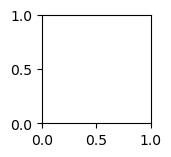

In [34]:
for i in range(9):
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(train_images[i], cmap=pyplot.get_cmap('gray'))
pyplot.show()

# Reshaping and Normalizing the Images

In [11]:
train_images[1]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  51, 159, 253, 159,  50,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  48, 238, 252, 252, 252, 237,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [12]:
train_images.shape

(60000, 28, 28)

In [13]:
# Normalize the images 
train_images = (train_images / 255) 
test_images = (test_images / 255) 





In [14]:
train_images[1]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [15]:

# Flatten the images. 28*28 = 784
train_images = train_images.reshape((-1, 784))
test_images = test_images.reshape((-1, 784))


In [16]:
train_images.shape

(60000, 784)

In [17]:
# Build the model.

model = Sequential()

model.add(Dense(64, activation='relu', input_shape=(784,)))
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))    
         
print(model.summary())        




/opt/conda/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

None


In [18]:

# Compile the model.
model.compile(optimizer='adam', loss='categorical_crossentropy',  metrics=['accuracy'],)



In [19]:
# Train the model.
model.fit(  train_images,  to_categorical(train_labels),  epochs=5,  batch_size=32,)

Epoch 1/5


W0000 00:00:1793028637.473729    7201 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 902us/step - accuracy: 0.9191 - loss: 0.2764
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 862us/step - accuracy: 0.9621 - loss: 0.1246
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 860us/step - accuracy: 0.9713 - loss: 0.0922
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 843us/step - accuracy: 0.9774 - loss: 0.0731
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 851us/step - accuracy: 0.9811 - loss: 0.0582


Let's put out trained model into a real test by evaluating its performance against unseen data from the testing set.

In [20]:
model.evaluate(test_images, to_categorical(test_labels))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 717us/step - accuracy: 0.9742 - loss: 0.0867


[0.08669403195381165, 0.9742000102996826]

The results are pretty good for 5 epochs and for such a simple model. We have achieved over 96% accuracy with such a basic model at such a short time.

Let's make individual predictions using our own hand writing. Open MS paint, create a small square-ish work space and draw your desired number using black colour.

Store your masterpiece as a "sample.png" file and upload it to your jupyter Notebook work space, in the same directory as this file.

In [30]:
import matplotlib.image as img 
my_img = img.imread('sample.png')

In [31]:
# our input image looks grey but in fact is a colour image.
# our model works with greyscale images only so let's convert our input image to greyscale

r, g, b = my_img[:,:,0], my_img[:,:,1], my_img[:,:,2]
gray_img = 0.2989 * r + 0.5870 * g + 0.1140 * b

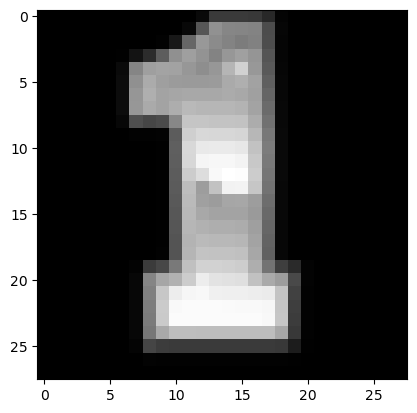

In [32]:
image_resized_gray = resize(gray_img,(28,28))
plt.imshow(image_resized_gray, cmap='gray')

In [33]:
pred = model.predict(image_resized_gray.reshape(-1, 784))
print("It seems to be ", pred.argmax())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
It seems to be  2
